# Évaluations avec cache et regroupement temporel — CVRPTW

## Périmètre et invariants

Cette étude complète v5 ; elle ne remplace pas ses résultats. Le problème reste le CVRPTW à distance DIMACS : chaque client exactement une fois, capacité limitée, fenêtres strictes sur le début du service, attente autorisée, retour au dépôt et flotte maximale. Les matrices, demandes, services et fenêtres sont inchangés. Les BKS ne sont lues qu’après les résolutions.

## Changements réellement implémentés

**Cache exact de préfixes.** `algo/cached_local.py` mémorise, après p clients inchangés, l’heure de départ, la distance parcourue et la charge cumulée. Lors d’un mouvement, l’évaluation repart de cet état et recalcule le suffixe modifié, puis le retour au dépôt. Les contrôles de capacité et de fenêtres restent complets sur cette partie. Le préfixe doit correspondre exactement au préfixe utilisé pour construire le cache ; cette précondition est assurée par les mouvements. Une inversion 2-opt conserve seulement le préfixe avant l’inversion. L’évaluation entière indépendante est conservée pour les solutions retournées.

Les tableaux sont dimensionnés selon la plus longue tournée actuelle et agrandis si nécessaire. Une première allocation selon le nombre total de clients était plus lente : le diagnostic négatif est conservé dans `initial_cache_diagnostic.md`. Les caches sont reconstruits après chaque mouvement ; nous ne prétendons pas à une évaluation constante de toute la recherche. Le recuit direct n’est pas accéléré par ce cache de recherche locale.

**Regroupement de tournées complètes.** `algo/temporal_groups.py` rapproche les clients selon la distance, l’attente minimale inévitable et le retard minimal inévitable entre leurs fenêtres. Le score dirigé est $d_{ij}+0,2\max(0,e_j-l_i-s_i-t_{ij})+\max(0,e_i+s_i+t_{ij}-l_j)$ ; le score symétrique retient le minimum des deux sens. Pour chaque tournée pivot tirée aléatoirement, les tournées partenaires sont classées par leur meilleur couple de clients. Le score est une heuristique de classement, pas un nouveau coût ni une preuve de faisabilité. Le nombre de clients par groupe et la limite de flotte gardent les règles de la référence.

`algo/cached_iterated.py` et `algo/experimental_v6.py` constituent des variantes explicites, pour conserver les sources de référence utilisées dans les anciennes mesures.

## Vitesse à travail identique

Les deux recherches locales exécutent les mêmes mouvements, mêmes graines, mêmes limites et mêmes solutions finales, sur six solutions réalisables à 1 000 clients produites précédemment. La compilation est exclue, l’ordre des deux variantes alterne et six répétitions sont réalisées sur un même cœur logique. Un ratio supérieur à 1 indique un gain. Les différences de quelques pour cent restent sensibles au bruit sur ces courtes mesures ; le gain observé sur R2 est plus marqué. Ce tableau ne démontre pas à lui seul une amélioration du gap.

| Instance | Cache s | Complet s | Ratio |
| --- | --- | --- | --- |
| C1_10_3 | 0,001 | 0,001 | 1,024 |
| C2_10_3 | 0,001 | 0,001 | 1,044 |
| R1_10_3 | 0,005 | 0,005 | 1,046 |
| R2_10_3 | 0,009 | 0,012 | 1,270 |
| RC1_10_3 | 0,003 | 0,003 | 1,106 |
| RC2_10_3 | 0,005 | 0,005 | 0,950 |

## Développement et ablation

48 résolutions, six instances `_10_5`, graines 1701 et 1702, plafond de 20 secondes. Les quatre variantes isolent cache seul, regroupement seul et combinaison. Les paramètres numériques de l’ILS restent ceux de la référence. La combinaison est retenue pour la confirmation avant lecture de ses résultats.

| Variante | Essais | Gap moyen % | Pire gap % |
| --- | --- | --- | --- |
| ILS de référence | 12 | 5,953 | 10,975 |
| Cache de préfixes | 12 | 5,665 | 10,339 |
| Cache et groupes temporels | 12 | 5,262 | 10,509 |
| Groupes temporels | 12 | 5,863 | 10,773 |

## Validation distincte à budget court

48 résolutions sur douze autres instances `_10_6` et `_10_7`, graines 1801 et 1802, plafond de 40 secondes. Les mêmes départs sont construits avec douze tentatives et vérifiés par paire ; leur construction est comptée séparément dans chaque résolution. Les six processus sont placés sur des cœurs logiques distincts ; le préchauffage est hors budget. Les géographies peuvent avoir figuré dans d’autres campagnes historiques : le lot est séparé du réglage v6, sans prétendre à une validation totalement aveugle.

| Méthode | Essais | Gap moyen % | Écart-type | Pire gap % | Sous 6 % | Sous 7 % | Recherche s | Total s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ILS de référence | 24 | 6,065 | 3,836 | 17,063 | 12 | 16 | 40,009 | 44,268 |
| Cache et groupes temporels | 24 | 6,164 | 3,735 | 15,468 | 12 | 13 | 40,010 | 44,339 |

L’amélioration moyenne appariée de la combinaison est **-0.099 point de pourcentage**, avec intervalle bootstrap exploratoire par instance **[-0.547 ; 0.318]**. Un nombre positif favorise la nouvelle variante. Les douze instances sont rééchantillonnées en conservant leurs deux graines ensemble. Deux graines restent limitées pour estimer la variabilité. Les résultats ne satisfont pas notre règle exploratoire de confirmation : le moteur de référence reste le défaut.

Les moyennes de ce nouveau lot ne se comparent pas directement aux 10,127 % de v5, mesurés sur d’autres instances. Chaque tableau inclut toutes les instances prévues et chaque méthode possède le même nombre de répétitions.

| instance | ILS de référence | Cache et groupes temporels |
| --- | --- | --- |
| C1_10_6 | 0,548 | 0,002 |
| C1_10_7 | 0,011 | 0,007 |
| C2_10_6 | 5,824 | 6,653 |
| C2_10_7 | 5,370 | 6,649 |
| R1_10_6 | 6,106 | 6,427 |
| R1_10_7 | 6,776 | 8,294 |
| R2_10_6 | 8,347 | 8,291 |
| R2_10_7 | 14,540 | 13,777 |
| RC1_10_6 | 4,614 | 4,596 |
| RC1_10_7 | 5,193 | 5,440 |
| RC2_10_6 | 6,397 | 5,317 |
| RC2_10_7 | 9,058 | 8,519 |

## Diagnostic ciblé à 120 secondes supplémentaires

Les trois cas difficiles connus repartent exactement de l’archive v5, graine 1901, avec 120 secondes pour la référence et 120 pour la variante. Ce sont six résolutions supplémentaires sur trois départs déjà optimisés, pas des départs neufs. Une seule graine par cas interdit une conclusion robuste sur la méthode à long budget.

| instance | Avant % | ILS de référence | Cache et groupes temporels |
| --- | --- | --- | --- |
| R2_10_3 | 9,049 | 7,837 | 7,341 |
| R2_10_4 | 10,443 | 8,781 | 8,941 |
| RC2_10_4 | 12,086 | 11,284 | 11,173 |

L’archive globale garde ses douze instances : neuf solutions sont inchangées et trois retiennent la meilleure solution réalisable des deux branches, choisie par distance. Les deux branches sont facturées, même si l’une n’améliore rien. Le gap moyen de cette archive est **4.749 %**, son pire cas **11.173 %**, pour un effort cumulé moyen **805.7 secondes par instance**, avec budgets désormais différents selon les cas. Ce n’est pas une moyenne de résolutions indépendantes de 40 ou 120 secondes et ce n’est pas une comparaison équitable du temps nécessaire à partir de zéro.

## Reproduction et limites

Les JSON, sources figées, empreintes, CSV et protocoles sont dans `results/optimization_v6/`. `python scripts/analyze_v6.py` revérifie les sources, les données, les couvertures, les capacités, les fenêtres, les retours, les distances et les départs appariés. Chaque reprise refuse un protocole différent ; une nouvelle expérience doit utiliser un nouveau `--label`.

Les tests différentiels couvrent aussi des distances non métriques, des temps de trajet distincts des distances et des fenêtres serrées. Une croissance de tournée créée par 2-opt* teste l’agrandissement des caches. Les temps restent dépendants du matériel et des mesures parallèles. Le trafic variable, plus de 1 000 clients et une garantie d’optimalité ne sont pas démontrés.

Sources : [Ribas et ses coauteurs, ILS pour le VRPTW](https://luizsatoru.github.io/conteudo/artigos/PAPER%20IESM2011-SABIR.pdf), [Vidal et ses coauteurs, informations de séquences et fenêtres](https://www.cirrelt.ca/documentstravail/cirrelt-2012-23.pdf). Les composants sont adaptés à notre code ; les performances des publications ne sont pas attribuées à notre solveur.


## Suivi exploratoire du cache seul

Après lecture de la confirmation de la combinaison, 24 résolutions supplémentaires isolent le cache seul sur les mêmes douze instances et graines, au même plafond de 40 secondes. Les 24 mesures ILS de référence déjà obtenues sont réutilisées, pas exécutées ni comptées une seconde fois. Les listes initiales de tournées sont comparées exactement par empreinte, au-delà de la seule égalité des coûts.

| Méthode | Mesures comparées | Gap moyen % | Pire gap % | Recherche s |
| --- | --- | --- | --- | --- |
| ILS de référence | 24 | 6,065 | 17,063 | 40,009 |
| Cache de préfixes | 24 | 6,207 | 14,406 | 40,009 |

Le gain apparié du cache seul est -0.142 point, intervalle exploratoire [-0.6981018356280242, 0.4289583459194053]. Cette analyse est effectuée après observation d’un autre candidat sur le même lot : elle ne remplace pas une confirmation indépendante et ne déclenche pas un changement de défaut. Ses essais ont été réalisés dans un lot séparé avec le même nombre de processus, ce qui ajoute une limite à la comparaison des temps. Les 24 nouveaux essais sont identifiés dans `cache_followup/` ; les tableaux de comparaison contiennent aussi les 24 références réutilisées.


## Ensemble de trois recherches depuis des départs neufs

Pour chaque couple instance/graine de la validation, une seconde combinaison utilise uniquement les trois trajectoires correspondantes : référence, variante combinée et cache seul. Elle ne lit ni archive historique, ni autre graine. Les 24 ensembles couvrent les douze instances et deux graines. Le partitionnement dispose d’au plus deux secondes et tous les temps de construction et de recherche des trois entrées sont facturés.

Le meilleur des trois essais atteint 5.608 % de gap moyen ; la recombinaison atteint **5.508 %**, avec pire gap **14.406 %** et effort cumulé moyen **132.7 secondes par ensemble**. Une grande part du gain vient donc de l’effort supplémentaire et du meilleur des trois essais ; l’apport marginal du partitionnement est plus faible. Nous n’avons pas exécuté de référence unique à partir de zéro avec ce même effort total : ce résultat ne démontre pas une supériorité à temps égal. Les 24 recombinaisons réutilisent des résolutions déjà comptées et ne sont pas 72 nouvelles recherches.

Le code `algo/portfolio_v6.py` fournit cette combinaison comme méthode explicite. La commande `python scripts/run_portfolio_v6.py R2_10_6 --seconds-per-search 40 --partition-seconds 2 --seed 1801` lance trois recherches, et non une résolution de 40 secondes. Cette nouvelle commande partage une seule construction initiale, alors que les mesures du tableau facturent les trois constructions effectivement réalisées dans les campagnes d’origine ; le temps de la commande doit être mesuré séparément. Son fonctionnement est testé, sans attribuer au nouveau point d’entrée une campagne complète non exécutée.

Les sorties individuelles de ces ensembles sont dans `cold_portfolio/flat.csv` et leurs sources sont vérifiables par empreinte. Cette option reste expérimentale ; le moteur de référence conserve son rôle de défaut.


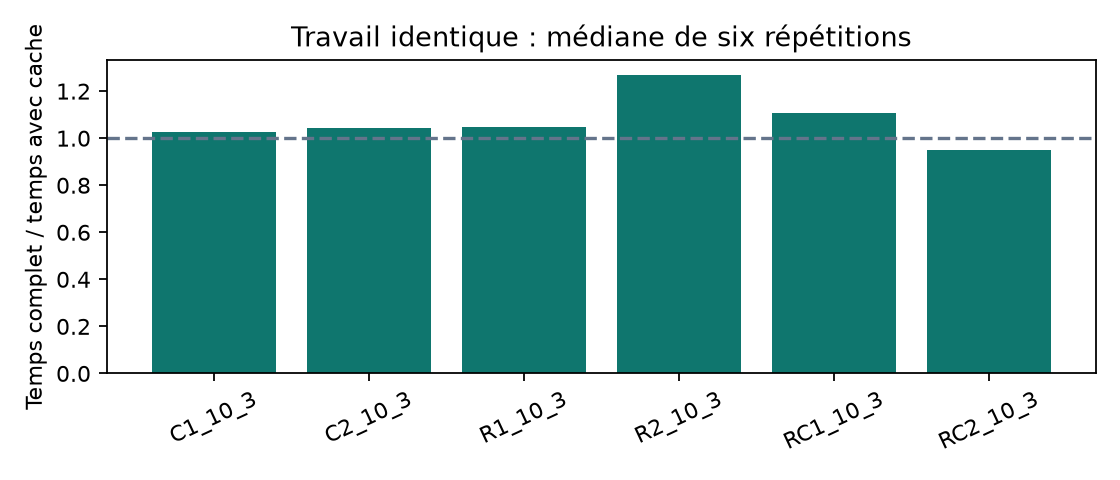

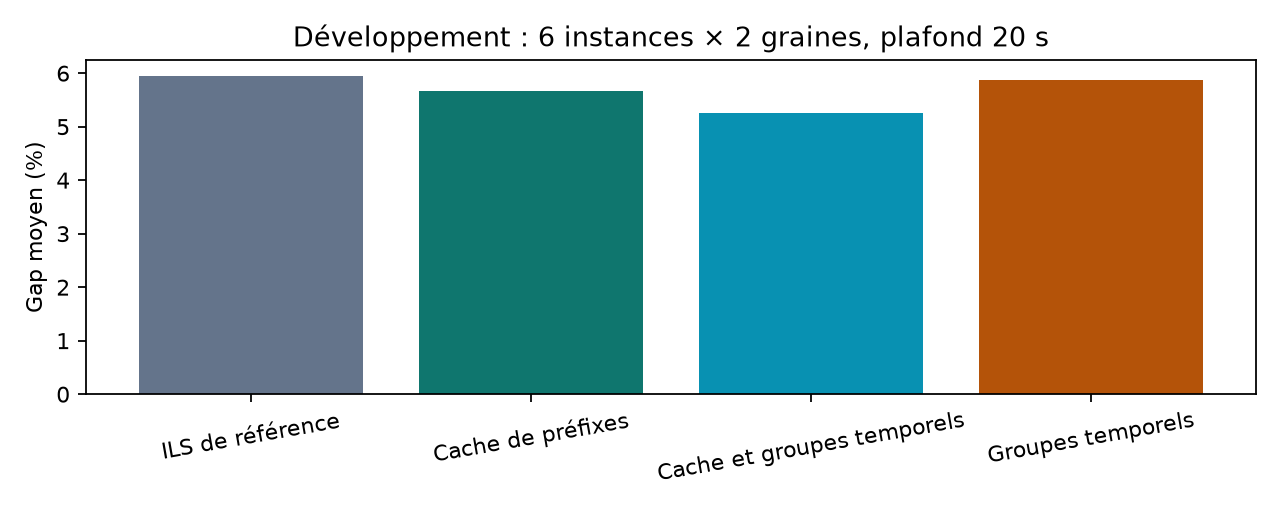

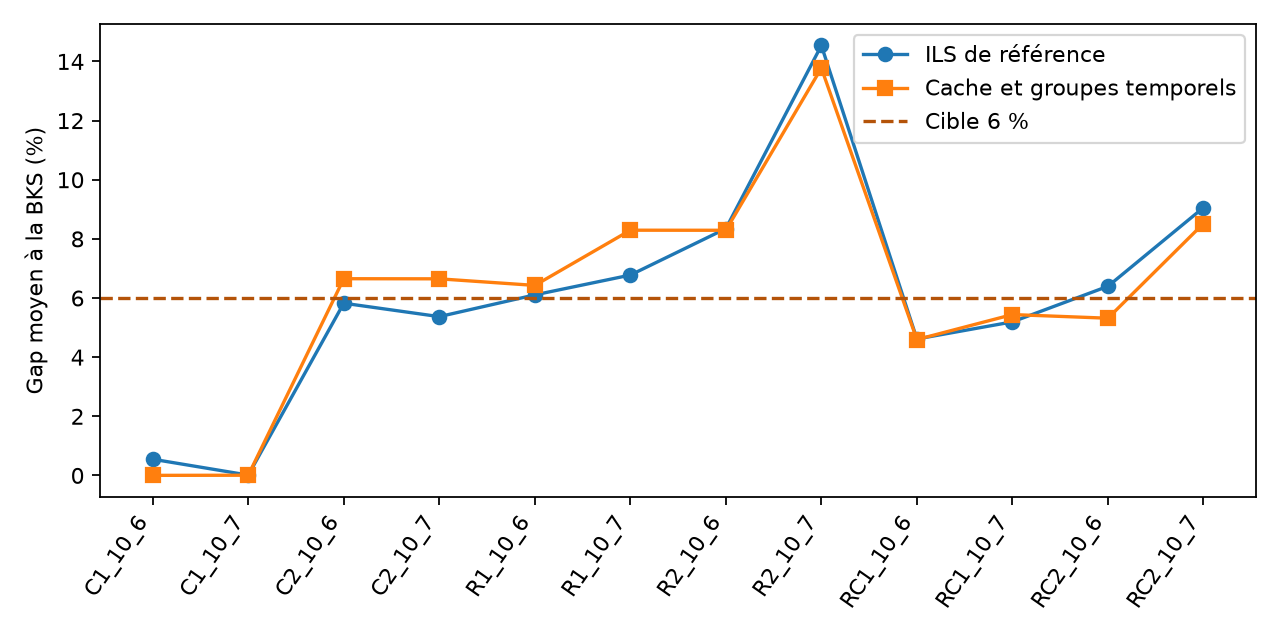

In [1]:
from pathlib import Path
from IPython.display import Image, display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'algo/experimental_v6.py').exists())
display(Image(filename=str(ROOT/'livraison/ils_v6_figures/speed.png')))
display(Image(filename=str(ROOT/'livraison/ils_v6_figures/development.png')))
display(Image(filename=str(ROOT/'livraison/ils_v6_figures/validation.png')))